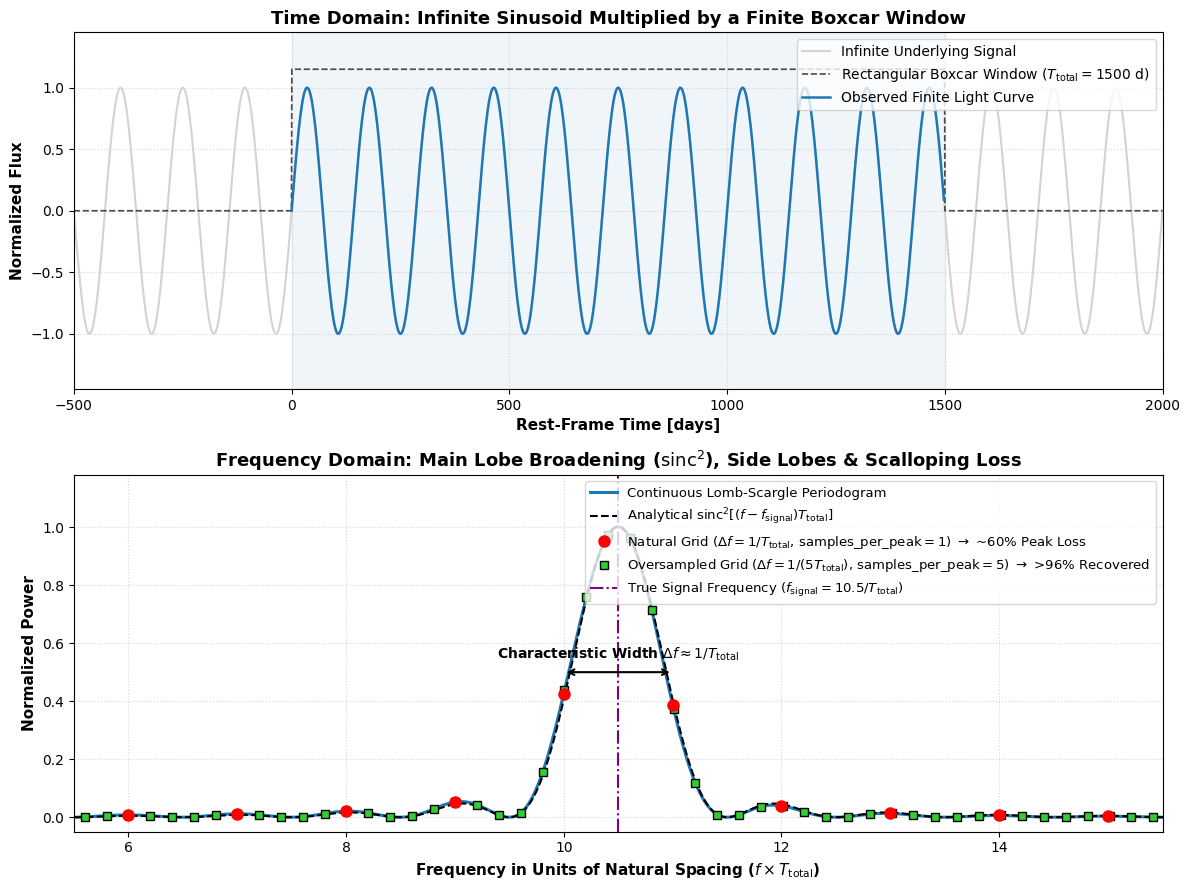

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

# 1. SIMULATION PARAMETERS (ZTF-like rest-frame baseline)
T_total = 1500.0  # Total observing baseline [days]
dt = 2.0          # Sampling cadence [days]

# Choose a signal frequency halfway between natural Fourier frequencies (10.5 / T_total)
# to clearly illustrate both the sinc^2 main lobe and scalloping loss
k_signal = 10.5
f_signal = k_signal / T_total  # ~0.007 day^-1 (Period ~ 142.8 days)

# 2. TIME DOMAIN: Infinite signal vs. Finite Rectangular (Boxcar) Window
t_extended = np.linspace(-600, T_total + 600, 3000)
y_infinite = np.sin(2.0 * np.pi * f_signal * t_extended)

# Rectangular window: 1 inside [0, T_total], 0 outside
window = np.where((t_extended >= 0) & (t_extended <= T_total), 1.0, 0.0)

# Observed discrete light curve inside [0, T_total]
t_obs = np.arange(0, T_total, dt)
y_obs = np.sin(2.0 * np.pi * f_signal * t_obs)

# 3. FREQUENCY DOMAIN: Periodogram & Theoretical sinc^2 Envelope
ls = LombScargle(t_obs, y_obs)

# High-resolution curve to trace the continuous sinc^2 shape
f_dense, p_dense = ls.autopower(
    normalization='standard',
    minimum_frequency=5.0 / T_total,
    maximum_frequency=16.0 / T_total,
    samples_per_peak=50
)

# Natural Fourier grid spacing: df = 1 / T_total (samples_per_peak = 1)
f_nat = np.arange(5, 17) / T_total
p_nat = ls.power(f_nat, normalization='standard')

# Standard oversampled grid: df = 1 / (5 * T_total) (samples_per_peak = 5)
f_spp5, p_spp5 = ls.autopower(
    normalization='standard',
    minimum_frequency=5.0 / T_total,
    maximum_frequency=16.0 / T_total,
    samples_per_peak=5
)

# Exact analytical power spectrum of a finite boxcar window: sinc^2((f - f_signal) * T_total)
# Note: np.sinc(x) = sin(pi * x) / (pi * x)
p_sinc2 = np.max(p_dense) * (np.sinc((f_dense - f_signal) * T_total) ** 2)

# 4. PLOTTING
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))

# --- Top Panel: Time Domain ---
ax1.plot(t_extended, y_infinite, color='lightgray', lw=1.5, label='Infinite Underlying Signal')
ax1.plot(t_extended, window * 1.15, 'k--', lw=1.2, alpha=0.7, label=f'Rectangular Boxcar Window ($T_{{\\rm total}} = {int(T_total)}$ d)')
ax1.plot(t_obs, y_obs, color='tab:blue', lw=1.8, label='Observed Finite Light Curve')
ax1.axvspan(0, T_total, color='tab:blue', alpha=0.07)

ax1.set_xlim(-500, T_total + 500)
ax1.set_ylim(-1.45, 1.45)
ax1.set_xlabel('Rest-Frame Time [days]', fontweight='bold', fontsize=11)
ax1.set_ylabel('Normalized Flux', fontweight='bold', fontsize=11)
ax1.set_title('Time Domain: Infinite Sinusoid Multiplied by a Finite Boxcar Window', fontweight='bold', fontsize=13)
ax1.legend(loc='upper right', fontsize=10)
ax1.grid(ls=':', alpha=0.5)

# --- Bottom Panel: Frequency Domain ---
ax2.plot(f_dense * T_total, p_dense, color='tab:blue', lw=2.2, label='Continuous Lomb-Scargle Periodogram')
ax2.plot(f_dense * T_total, p_sinc2, 'k--', lw=1.5, label=r'Analytical $\mathrm{sinc}^2[(f - f_{\rm signal}) T_{\rm total}]$')

# Compare samples_per_peak=1 vs samples_per_peak=5
ax2.plot(f_nat * T_total, p_nat, 'ro', ms=8, zorder=5,
         label=r'Natural Grid ($\Delta f = 1/T_{\rm total}$, $\mathrm{samples\_per\_peak}=1$) $\rightarrow$ ~60% Peak Loss')
ax2.plot(f_spp5 * T_total, p_spp5, 's', color='limegreen', markeredgecolor='black', ms=6, zorder=4,
         label=r'Oversampled Grid ($\Delta f = 1/(5 T_{\rm total})$, $\mathrm{samples\_per\_peak}=5$) $\rightarrow$ >96% Recovered')

# Highlight true signal frequency and first nulls (f_signal +/- 1/T_total)
ax2.axvline(k_signal, color='purple', ls='-.', lw=1.5, label=f'True Signal Frequency ($f_{{\\rm signal}} = {k_signal}/T_{{\\rm total}}$)')
ax2.annotate(
    '', xy=(k_signal - 0.5, 0.5), xytext=(k_signal + 0.5, 0.5),
    arrowprops=dict(arrowstyle='<->', color='black', lw=1.5)
)
ax2.text(k_signal, 0.53, r'Characteristic Width $\Delta f \approx 1/T_{\rm total}$',
         ha='center', va='bottom', fontweight='bold', fontsize=10)

ax2.set_xlim(5.5, 15.5)
ax2.set_ylim(-0.05, 1.18)
ax2.set_xlabel(r'Frequency in Units of Natural Spacing ($f \times T_{\rm total}$)', fontweight='bold', fontsize=11)
ax2.set_ylabel('Normalized Power', fontweight='bold', fontsize=11)
ax2.set_title(r'Frequency Domain: Main Lobe Broadening ($\mathrm{sinc}^2$), Side Lobes & Scalloping Loss', fontweight='bold', fontsize=13)
ax2.legend(loc='upper right', fontsize=9.5)
ax2.grid(ls=':', alpha=0.5)

plt.tight_layout()
plt.show()

Colunas disponiveis no CSV: ['RA_fvar', 'DEC_fvar', 'variability_g', 'variability_err_g', 'FILE_NAME', 'SDSS_NAME_1', 'PLATE_1', 'MJD_1', 'FIBERID_1', 'RA', 'DEC', 'Z', 'SNR', 'u_SDSS', 'g_SDSS', 'r_SDSS', 'i_SDSS', 'z_SDSS', 'g_HSC', 'r_HSC', 'i_HSC', 'z_HSC', 'y_HSC', 'FIELD', 'IS_QSO2', 'PL_slope', 'PL_slope_err', 'PL_norm', 'PL_norm_err', 'POLY_a', 'POLY_a_err', 'POLY_b', 'POLY_b_err', 'POLY_c', 'POLY_c_err', 'Fe_flux', 'Fe_flux_err', 'Fe_uv_norm', 'Fe_uv_norm_err', 'Fe_uv_FWHM', 'Fe_uv_FWHM_err', 'Fe_uv_shift', 'Fe_uv_shift_err', 'Fe_op_norm', 'Fe_op_norm_err', 'Fe_op_FWHM', 'Fe_op_FWHM_err', 'Fe_op_shift', 'Fe_op_shift_err', 'L5100', 'L5100_err', 'Fpeak_Hb_na_NLR_1', 'Fpeak_err_Hb_na_NLR_1', 'v_Hb_na_NLR_1', 'v_err_Hb_na_NLR_1', 'sig_Hb_na_NLR_1', 'sig_err_Hb_na_NLR_1', 'Fpeak_Hb_br_NLR_1', 'Fpeak_err_Hb_br_NLR_1', 'v_Hb_br_NLR_1', 'v_err_Hb_br_NLR_1', 'sig_Hb_br_NLR_1', 'sig_err_Hb_br_NLR_1', 'Fpeak_Hb_br_BLR_1', 'Fpeak_err_Hb_br_BLR_1', 'v_Hb_br_BLR_1', 'v_err_Hb_br_BLR_1', 'si

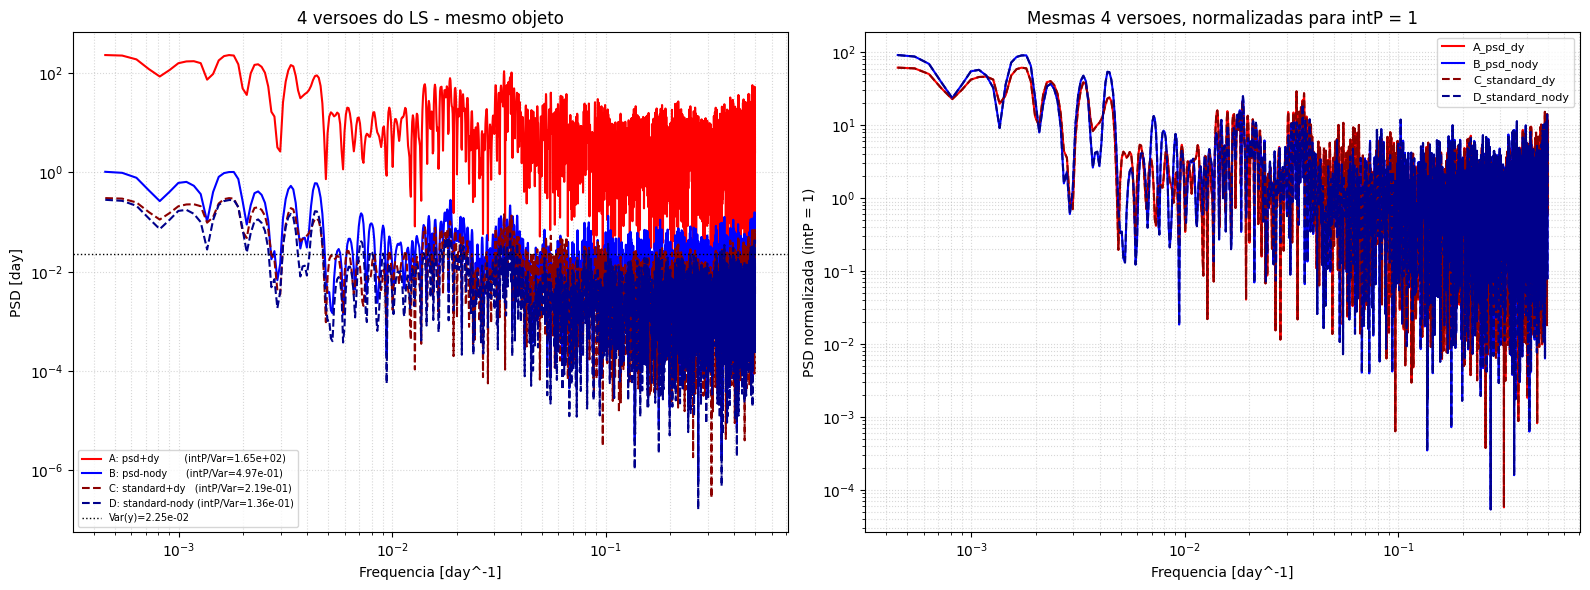


Relatorio salvo: test_real_ls_4versions.txt
Plot salvo: test_real_ls_4versions.png


In [4]:
#!/usr/bin/env python3
"""
Teste real: LS com 'psd'/'standard' x com/sem dy, no MESMO objeto.
Mostra a forma e a escala de cada versão.
"""

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

# ---- Configuracao ----
BASE_DIR = r"ztffp_final_data_2025"
CSV_META = r"Cross_15_luiz.csv"     # <-- NOME NOVO
BAND = 'g'
OUT_PLOT = 'test_real_ls_4versions.png'
OUT_REPORT = 'test_real_ls_4versions.txt'

# ---- Carrega CSV e valida colunas ----
meta = pd.read_csv(CSV_META)
print(f"Colunas disponiveis no CSV: {list(meta.columns)}")

# Aceita varios nomes alternativos para RA/DEC
ra_col  = next((c for c in meta.columns if c.upper() in ('RA', 'RA_DEG', 'RAJ2000')), None)
dec_col = next((c for c in meta.columns if c.upper() in ('DEC', 'DEC_DEG', 'DEJ2000')), None)
if ra_col is None or dec_col is None:
    raise ValueError(f"CSV nao tem coluna de RA ou DEC. Colunas: {list(meta.columns)}")

print(f"Usando RA='{ra_col}', DEC='{dec_col}'")

# ---- Pega primeiro objeto valido ----
folders = [f for f in os.listdir(BASE_DIR)
           if os.path.isdir(os.path.join(BASE_DIR, f)) and "plots" not in f]

txt_path, ra, dec = None, None, None
for folder in folders:
    try:
        ra_f, dec_f = map(float, folder.split('_'))
    except:
        continue
    txts = glob.glob(os.path.join(BASE_DIR, folder, f"*_ztf_{BAND}_filtered.txt"))
    if txts:
        txt_path, ra, dec = txts[0], ra_f, dec_f
        break

if txt_path is None:
    raise FileNotFoundError(f"Nenhum arquivo *_ztf_{BAND}_filtered.txt encontrado em {BASE_DIR}")

print(f"Objeto escolhido: RA={ra}, DEC={dec}")
print(f"Arquivo: {txt_path}")

# ---- Carrega e normaliza ----
df = pd.read_csv(txt_path).sort_values('mjd')
t = df['mjd'].values
f = df['flux'].values
err = df['fluxe'].values if 'fluxe' in df.columns else np.zeros_like(f)

# Coadd noturno
day_ids = np.floor(t).astype(int)
unique_days = np.unique(day_ids)
t_d, f_d, e_d = [], [], []
for d in unique_days:
    m = (day_ids == d)
    if np.sum(m) == 1:
        t_d.append(t[m][0]); f_d.append(f[m][0]); e_d.append(err[m][0])
    else:
        w = 1.0 / (err[m] ** 2 + 1e-30)
        t_d.append(np.mean(t[m]))
        f_d.append(np.sum(w * f[m]) / np.sum(w))
        e_d.append(1.0 / np.sqrt(np.sum(w)))

t_d = np.array(t_d); f_d = np.array(f_d); e_d = np.array(e_d)
print(f"Pontos apos coadd: {len(t_d)} (originais: {len(t)})")

# Normalizacao fracionaria
med = np.median(f_d)
y = (f_d - med) / med
dy = e_d / med

print(f"Var(y) = {np.var(y):.4e}")
print(f"median(dy) = {np.median(dy):.4e}")
print(f"T_baseline = {t_d.max() - t_d.min():.1f} d")

f_min = 1.0 / (t_d.max() - t_d.min())
f_max = 0.5

# ---- 4 versoes do LS ----
results = {}

ls = LombScargle(t_d, y, dy=dy, fit_mean=True, center_data=True)
f_A, p_A = ls.autopower(normalization='psd', minimum_frequency=f_min,
                        maximum_frequency=f_max, samples_per_peak=5)
results['A_psd_dy'] = (f_A, p_A)

ls = LombScargle(t_d, y, fit_mean=True, center_data=True)
f_B, p_B = ls.autopower(normalization='psd', minimum_frequency=f_min,
                        maximum_frequency=f_max, samples_per_peak=5)
results['B_psd_nody'] = (f_B, p_B)

ls = LombScargle(t_d, y, dy=dy, fit_mean=True, center_data=True)
f_C, p_C = ls.autopower(normalization='standard', minimum_frequency=f_min,
                        maximum_frequency=f_max, samples_per_peak=5)
results['C_standard_dy'] = (f_C, p_C)

ls = LombScargle(t_d, y, fit_mean=True, center_data=True)
f_D, p_D = ls.autopower(normalization='standard', minimum_frequency=f_min,
                        maximum_frequency=f_max, samples_per_peak=5)
results['D_standard_nody'] = (f_D, p_D)

# ---- Estatisticas ----
def stats(freq, power):
    pos = power[power > 0]
    return {
        'min_y': float(np.nanmin(pos)) if len(pos) > 0 else np.nan,
        'max_y': float(np.nanmax(power)),
        'median_y': float(np.nanmedian(power)),
        'integral': float(np.trapz(power, freq)) if len(freq) > 1 else np.nan,
    }

var_y = float(np.var(y))
print("\n" + "=" * 80)
print("RESULTADOS")
print("=" * 80)
print(f"Var(y) = {var_y:.4e}")
header = f"{'Versao':<20} {'min(y)':>12} {'max(y)':>12} {'median(y)':>12} {'intP':>12} {'intP/Var':>12}"
print(header)
print("-" * 80)

stats_dict = {}
for name, (fr, pw) in results.items():
    st = stats(fr, pw)
    st['integral_over_var'] = st['integral'] / var_y
    stats_dict[name] = st
    print(f"{name:<20} {st['min_y']:>12.3e} {st['max_y']:>12.3e} "
          f"{st['median_y']:>12.3e} {st['integral']:>12.3e} {st['integral_over_var']:>12.3e}")

print("\n" + "=" * 80)
print("RAZOES ENTRE VERSOES (median(y) de cada)")
print("=" * 80)
print(f"median(A_psd_dy) / median(B_psd_nody)   = "
      f"{stats_dict['A_psd_dy']['median_y']/stats_dict['B_psd_nody']['median_y']:.3e}")
print(f"median(C_std_dy) / median(D_std_nody)   = "
      f"{stats_dict['C_standard_dy']['median_y']/stats_dict['D_standard_nody']['median_y']:.3e}")
print(f"median(A_psd_dy) / median(C_std_dy)     = "
      f"{stats_dict['A_psd_dy']['median_y']/stats_dict['C_standard_dy']['median_y']:.3e}")
print(f"median(B_psd_nody) / median(D_std_nody) = "
      f"{stats_dict['B_psd_nody']['median_y']/stats_dict['D_standard_nody']['median_y']:.3e}")

print("\n" + "=" * 80)
print("CORRELACAO DE FORMA (log PSD)")
print("=" * 80)
pairs = [('A_psd_dy', 'C_standard_dy'),
         ('B_psd_nody', 'D_standard_nody'),
         ('A_psd_dy', 'B_psd_nody'),
         ('C_standard_dy', 'D_standard_nody')]
for a, b in pairs:
    fa, pa = results[a]; fb, pb = results[b]
    pb_on_a = np.interp(fa, fb, pb)
    mask = (pa > 0) & (pb_on_a > 0)
    if np.sum(mask) > 10:
        corr = np.corrcoef(np.log10(pa[mask]), np.log10(pb_on_a[mask]))[0, 1]
        ratio = pa[mask] / pb_on_a[mask]
        print(f"{a:<20} vs {b:<20}: corr={corr:.4f}, "
              f"median(P_a/P_b)={np.median(ratio):.3e}, "
              f"IQR=[{np.percentile(ratio, 25):.3e}, {np.percentile(ratio, 75):.3e}]")

# ---- Plot ----
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
ax.loglog(f_A, p_A, '-',  color='red',      lw=1.5,
          label=f"A: psd+dy        (intP/Var={stats_dict['A_psd_dy']['integral_over_var']:.2e})")
ax.loglog(f_B, p_B, '-',  color='blue',     lw=1.5,
          label=f"B: psd-nody      (intP/Var={stats_dict['B_psd_nody']['integral_over_var']:.2e})")
ax.loglog(f_C, p_C, '--', color='darkred',  lw=1.5,
          label=f"C: standard+dy   (intP/Var={stats_dict['C_standard_dy']['integral_over_var']:.2e})")
ax.loglog(f_D, p_D, '--', color='darkblue', lw=1.5,
          label=f"D: standard-nody (intP/Var={stats_dict['D_standard_nody']['integral_over_var']:.2e})")
ax.axhline(var_y, color='black', ls=':', lw=1, label=f'Var(y)={var_y:.2e}')
ax.set_xlabel('Frequencia [day^-1]')
ax.set_ylabel('PSD [day]')
ax.set_title('4 versoes do LS - mesmo objeto')
ax.legend(fontsize=7)
ax.grid(ls=':', alpha=0.5, which='both')

ax = axes[1]
for name, (fr, pw) in results.items():
    st = stats_dict[name]
    pw_norm = pw / st['integral'] if st['integral'] > 0 else pw
    color = {'A_psd_dy': 'red', 'B_psd_nody': 'blue',
             'C_standard_dy': 'darkred', 'D_standard_nody': 'darkblue'}[name]
    ls = '-' if 'psd' in name else '--'
    ax.loglog(fr, pw_norm, ls, color=color, lw=1.5, label=name)
ax.set_xlabel('Frequencia [day^-1]')
ax.set_ylabel('PSD normalizada (intP = 1)')
ax.set_title('Mesmas 4 versoes, normalizadas para intP = 1')
ax.legend(fontsize=8)
ax.grid(ls=':', alpha=0.5, which='both')

plt.tight_layout()
plt.savefig(OUT_PLOT, dpi=150)
plt.show()

# ---- Relatorio (UTF-8) ----
with open(OUT_REPORT, 'w', encoding='utf-8') as fo:
    fo.write("TESTE REAL: LS COM 'psd'/'standard' x COM/SEM dy\n")
    fo.write("=" * 60 + "\n")
    fo.write(f"CSV usado: {CSV_META}\n")
    fo.write(f"Colunas do CSV: {list(meta.columns)}\n")
    fo.write(f"Objeto: RA={ra}, DEC={dec}\n")
    fo.write(f"Arquivo: {txt_path}\n")
    fo.write(f"N pontos apos coadd: {len(t_d)}\n")
    fo.write(f"Var(y) = {var_y:.4e}\n")
    fo.write(f"median(dy) = {np.median(dy):.4e}\n")
    fo.write(f"T_baseline = {t_d.max() - t_d.min():.1f} d\n\n")
    fo.write(f"{'Versao':<20} {'min(y)':>12} {'max(y)':>12} {'median(y)':>12} {'intP':>12} {'intP/Var':>12}\n")
    fo.write("-" * 80 + "\n")
    for name, st in stats_dict.items():
        fo.write(f"{name:<20} {st['min_y']:>12.3e} {st['max_y']:>12.3e} "
                 f"{st['median_y']:>12.3e} {st['integral']:>12.3e} {st['integral_over_var']:>12.3e}\n")

print(f"\nRelatorio salvo: {OUT_REPORT}")
print(f"Plot salvo: {OUT_PLOT}")